In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from scipy.spatial.distance import cdist

def cluster_and_order_by_pca(nodes, Y, num_clusters=None, method='kmeans', eps=0.1, min_samples=3, plot=True, pca_space=True):
    # ---------- PCA projection of ALL points ----------
    pca = PCA(n_components=2)
    Y_2d = pca.fit_transform(Y)

    # ---------- Clustering ----------
    if method == 'kmeans':
        if num_clusters is None:
            num_clusters = int(np.sqrt(len(nodes)))  # heuristic
        clustering = KMeans(n_clusters=num_clusters, random_state=0).fit(Y)
        labels = clustering.labels_
        centroids_array = clustering.cluster_centers_
    elif method == 'dbscan':
        clustering = DBSCAN(eps=eps, min_samples=min_samples).fit(Y)
        labels = clustering.labels_
        unique_labels = [l for l in set(labels) if l != -1]
        centroids_array = np.array([Y_2d[labels == l].mean(axis=0) for l in unique_labels])
    else:
        raise ValueError("method must be 'kmeans' or 'dbscan'")

    # ---------- Cluster dictionary ----------
    centroids_pca = pca.transform(centroids_array)
    clusters = {}
    for node, label in zip(nodes, labels):
        clusters.setdefault(label, []).append(node)

    centroids = {i: centroids_array[i] for i in range(len(centroids_array))}
    cluster_ids = list(centroids.keys())

    # ---------- Order clusters by centroid proximity ----------
    X_2d = np.array([centroids[cid] for cid in cluster_ids])
    dist_matrix = cdist(X_2d, X_2d)
    ordered = [0]
    visited = set(ordered)
    while len(ordered) < len(cluster_ids):
        last = ordered[-1]
        next_cand = np.argmin([dist_matrix[last, j] if j not in visited else np.inf
                               for j in range(len(cluster_ids))])
        ordered.append(next_cand)
        visited.add(next_cand)
    ordered_clusters = [cluster_ids[i] for i in ordered]

    # ---------- Visualization ----------
    if plot:
        if not pca_space:
            Y_2d = Y  # use original space if not PCA
        else:
            X_2d = centroids_pca
        plt.figure(figsize=(7, 6))
        scatter = plt.scatter(Y_2d[:, 0], Y_2d[:, 1], c=labels, cmap='tab10', s=80, alpha=0.8)
        
        # Annotate each node
        for i, node in enumerate(nodes):
            plt.text(Y_2d[i, 0], Y_2d[i, 1], str(node), fontsize=8, ha='center', va='center', alpha=0.7)

        # Plot centroids
        plt.scatter(X_2d[:, 0], X_2d[:, 1], c='black', marker='x', s=120, label='Centroids')
        for i, cid in enumerate(cluster_ids):
            plt.text(X_2d[i, 0], X_2d[i, 1], f"C{cid}", fontsize=10, ha='center', va='center', fontweight='bold')

        # Connect centroids in ordered sequence
        # plt.plot(X_2d[ordered, 0], X_2d[ordered, 1], 'k--', alpha=0.6, linewidth=1.5)
        plt.title("Clusters in PCA-Reduced 2D Space")
        plt.colorbar(scatter, label='Cluster ID')
        plt.legend(loc='best', fontsize=8)
        plt.tight_layout()
        plt.show()

    # Return everything useful
    pca_coords = {cid: X_2d[i] for i, cid in enumerate(cluster_ids)}
    return clusters, ordered_clusters, pca_coords


In [20]:
import networkx as nx
from collections import deque

def weighted_bfs(G: nx.Graph, source=None, weight='weight'):
    """
    Performs a BFS traversal of a weighted graph,
    prioritizing neighbors connected via higher-weight edges.

    Parameters
    ----------
    G : nx.Graph or nx.DiGraph
        Input weighted graph.
    source : node (optional)
        Starting node for BFS. If None, uses an arbitrary node.
    weight : str
        Edge attribute name to use as weight (default 'weight').

    Returns
    -------
    order : list
        List of nodes in the order they were visited.
    """
    if source is None:
        source = list(G.nodes())[0]

    visited = set([source])
    queue = deque([source])
    order = []

    while queue:
        u = queue.popleft()
        order.append(u)

        # Sort neighbors by descending edge weight
        neighbors = sorted(
            G.neighbors(u),
            key=lambda v: G[u][v].get(weight, 1),
            reverse=True
        )

        for v in neighbors:
            if v not in visited:
                visited.add(v)
                queue.append(v)

    return order


In [ ]:
import networkx as nx
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from math import log, ceil
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXGate, RZZGate
from collections import defaultdict
import random
from tqdm import tqdm
from collections import deque
import networkx as nx
from collections import deque
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

def dfs_spanning_tree(G, root=0, directed_tree=False):
    if directed_tree:
        T = nx.DiGraph()
    else:
        T = nx.Graph()
    visited = set()

    def dfs(current):
        visited.add(current)
        if G.is_directed():
            neighbors = G.successors(current)  # outgoing edges only
        else:
            neighbors = G.neighbors(current)  # undirected or ignore direction

        for neighbor in neighbors:
            if neighbor not in visited:
                T.add_edge(current, neighbor)
                dfs(neighbor)

    dfs(root)
    return T

def weighted_dfs_spanning_tree(G: nx.Graph, root=None, weight='weight', branching=3):
    if root is None:
        root = list(G.nodes())[0]

    visited = set()
    T = nx.Graph()

    def dfs(u):
        # Sort neighbors by descending edge weight
        neighbors = sorted(
            G.neighbors(u),
            key=lambda v: G[u][v].get(weight, 1),
            reverse=True
        )
        candidates=[]
        for v in neighbors:
            if v not in visited:
                candidates.append(v)
        candidates=candidates[:branching]
        for v in candidates:  # limit branching factor
                T.add_edge(u, v)
                visited.add(v)
        for v in candidates:
            dfs(v)
    visited.add(root)
    dfs(root)
    return T

def build_tree_cluster(G, source, n):
    """
    Grow a connected cluster (tree) from `source` by BFS until it has `n` nodes.
    Returns the set of nodes in the cluster and the tree edges.
    """
    visited = set([source])
    tree_edges = []
    queue = deque([source])

    while len(visited) < n and queue:
        current = queue.popleft()
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                tree_edges.append((current, neighbor))
                queue.append(neighbor)
                if len(visited) == n:
                    break

    return G.subgraph(visited)

import networkx as nx
import random

def bfs_subgraph_clusters(H, n_clusters, cluster_size, start_node=None):
    """
    Partition a hardware graph H into n_clusters disjoint BFS-based regions
    of size `cluster_size`.

    Parameters
    ----------
    H : networkx.Graph
        The hardware topology (undirected or directed).
    n_clusters : int
        Number of logical clusters (same number of hardware BFS regions).
    cluster_size : int
        Number of nodes (qubits) per BFS region.
    start_node : int, optional
        Starting node for the first BFS cluster.

    Returns
    -------
    regions : list[set]
        List of sets, each containing the nodes in one BFS cluster.
    """
    visited = set()
    regions = []

    # Start BFS from central nodes if not provided
    if start_node is None:
        start_node = max(H.nodes, key=lambda x: H.degree(x))
    queue = [start_node]

    i=0
    while i < n_clusters:
        # Find next unvisited start node
        while queue and queue[0] in visited:
            queue.pop(0)
        # print(i,queue,visited)
        if not queue:
            # Fallback: pick next unvisited node (most connected)
            unvisited = [n for n in H.nodes if n not in visited]
            if not unvisited:
                break
            next_root = max(unvisited, key=lambda x: H.degree(x))
            queue = [next_root]
        root = queue[0]

        # Build BFS cluster
        q = [root]
        cluster_nodes = set()
        visited.add(root)

        while q and len(cluster_nodes) < cluster_size:
            node = q.pop(0)
            cluster_nodes.add(node)
            visited.add(node)
            for nbr in H.neighbors(node):
                if nbr not in visited:
                    q.append(nbr)
                    queue.append(nbr)

        if len(cluster_nodes) == cluster_size:
            regions.append(cluster_nodes)
            i+=1

    return regions


def get_coupling_graph(backend):
    edges = backend.configuration().coupling_map
    G = nx.Graph()
    G.add_edges_from(edges)
    return G

def find_linear_chain(backend, target_length):
    coupling_map = backend.coupling_map

    # adjacency as a dict: {qubit: [connected_qubits]}
    adj = {i: [] for i in range(backend.configuration().num_qubits)}
    for (i, j) in coupling_map:
        adj[i].append(j)
        adj[j].append(i)

    def dfs(node, visited, path):
        if len(path) == target_length:
            return path
        for neighbor in adj[node]:
            if neighbor not in visited:
                result = dfs(neighbor, visited | {neighbor}, path + [neighbor])
                if result:
                    return result
        return None

    for start in adj:
        result = dfs(start, {start}, [start])
        if result:
            return result
    return None

import numpy as np
import networkx as nx
from numpy.linalg import eig
from scipy.linalg import eigh

def graph_laplacian_embedding(G, k=2, alpha=0.95, normalized=False):
    # Step 0: adjacency matrix
    if isinstance(G, nx.DiGraph):
        W = nx.to_numpy_array(G, nodelist=sorted(G.nodes()), weight=None)
        n = W.shape[0]
        e = np.ones((n, 1))

        # Out-degree diagonal matrix
        out_degrees = W.sum(axis=1)
        D0 = np.diag(out_degrees)

        # Step 1: Transition probability matrix P with perturbation
        mu = np.where(out_degrees == 0, 1, 0).reshape(-1, 1)  # dangling nodes
        D0_inv = np.linalg.pinv(D0)  # use pseudo-inverse to handle zeros
        P = alpha * (D0_inv @ W + (1/n) * mu @ e.T) + (1 - alpha) * (1/n) * e @ e.T

        # Step 2: Solve eigenproblem π^T P = π^T, i.e., find stationary distribution
        # Equivalent to solving P^T π = π
        eigvals, eigvecs = eig(P.T)
        idx = np.argmin(np.abs(eigvals - 1))  # eigenvalue closest to 1
        pi = np.real(eigvecs[:, idx])
        pi = pi / pi.sum()  # normalize so sum=1

        # Step 3: Construct Laplacian
        Phi = np.diag(pi)
        L = Phi - (Phi @ P + P.T @ Phi) / 2

        # Step 4: Generalized eigenvalue problem L v = λ Φ v
        eigvals, eigvecs = eig(np.linalg.pinv(Phi) @ L)
        eigvals = np.real(eigvals)
        eigvecs = np.real(eigvecs)

        # Sort eigenvectors by eigenvalues
        idx = np.argsort(eigvals)
        eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]

        # Skip the first trivial eigenvector (corresponding to eigenvalue ~0)
        Y = eigvecs[:, 1:k+1]
        # Y=[]
        # for i in range(n):
        #     Y.append([np.mean(eigvecs[i,1:k+1]), np.std(eigvecs[i,1:k+1])])
        # Y = np.array(Y)
        return Y
    elif isinstance(G, nx.Graph):
        if normalized:
            A = adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            degrees = np.sum(A, axis=1)
            D_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(degrees, 1e-12)))

            # --- Normalized Laplacian ---
            L_sym = np.eye(G.number_of_nodes()) - D_inv_sqrt @ A @ D_inv_sqrt

            # --- Compute eigenvalues and eigenvectors ---
            vals, vecs = eigh(L_sym)
            # Sort eigenpairs
            idx = np.argsort(vals)
            vals, vecs = vals[idx], vecs[:, idx]

            # Skip the first eigenvector (constant)
            X = vecs[:, 1:k+1]
        else:
            adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            L = laplacian(adj_matrix)
            vals, vecs = eigh(L)
            X = vecs[:, 1:k+1]  # skip the first (trivial) eigenvector
        return X
    else:
        return None
    
import matplotlib.pyplot as plt
def gradient_graph(graph : nx.Graph, normalized=False, tree=None, title=None, flip_sign=False):
    if not tree:
        tree = graph
    G = nx.Graph()
    G.add_nodes_from(sorted(graph.nodes()))
    G.add_edges_from(graph.edges())
    graph=G
    fiedler = graph_laplacian_embedding(tree, k=1, normalized=normalized).flatten()
    # sorted_nodes = np.argsort(fiedler)

    fiedler_dict = {}
    fiedler_dict = {list(graph.nodes)[i] : (1+2*flip_sign*(-1))*fiedler[i] for i in range(graph.number_of_nodes())}

    values = [fiedler_dict[node] for node in graph.nodes()]
    n = G.number_of_nodes()
    side = math.ceil(math.sqrt(n))
    rows = math.ceil(n / side)
    pos = {
        node: (i % side, (i // side))  # bottom-to-top layout
        for i, node in enumerate(list(range(n)))
    }
    nx.draw(graph, pos, node_color=values, cmap=plt.cm.viridis, with_labels=True)
    # plt.colorbar(label="Fiedler Vector Value")
    if title:
        plt.title(title)
    plt.show()

def relabel_02n(G):
    # Create a mapping from old labels to new integer labels
    old_labels = list(G.nodes())
    mapping = {old_label: new_label for new_label, old_label in enumerate(old_labels)}
    
    # Relabel the graph
    G_relabelled = nx.relabel_nodes(G, mapping, copy=True)
    
    # Store the old labels as node attributes
    for new_label, old_label in mapping.items():
        G_relabelled.nodes[old_label]['old_label'] = new_label

    mapping = {new_label: old_label for new_label, old_label in enumerate(old_labels)}
    return G_relabelled, mapping  # Also return the mapping for reference

from numpy.linalg import eig

def graph_fiedler_sort(graph, normalized=False):
    fiedler = graph_laplacian_embedding(graph, k=1, normalized=normalized).flatten()
    sorted_nodes = np.argsort(fiedler)
    return sorted_nodes

def build_bfs_tree(G, source):
    """
    Build a BFS tree from a graph starting at the given source node.
    
    Parameters:
    - G: networkx.Graph or networkx.DiGraph
    - source: node in G from which BFS starts

    Returns:
    - T: networkx.DiGraph representing the BFS tree
    """
    bfs_edges = list(nx.bfs_edges(G, source))
    
    T = nx.Graph()  # BFS tree is rooted and directed
    T.add_nodes_from(G.nodes())
    T.add_edges_from(bfs_edges)

    return T

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from scipy.spatial.distance import cdist

def cluster_embedding(nodes, Y, num_clusters=None, method='kmeans', eps=0.1, min_samples=3, plot=False):
    if method == 'kmeans':
        if num_clusters is None:
            num_clusters = int(np.sqrt(len(nodes)))  # simple heuristic
        clustering = KMeans(n_clusters=num_clusters, random_state=0).fit(Y)
        labels = clustering.labels_
        centroids_array = clustering.cluster_centers_
    elif method == 'dbscan':
        clustering = DBSCAN(eps=eps, min_samples=min_samples).fit(Y)
        labels = clustering.labels_

        # Compute centroids manually (ignore noise label = -1)
        unique_labels = [l for l in set(labels) if l != -1]
        centroids_array = np.array([
            Y[labels == l].mean(axis=0) for l in unique_labels
        ])
    else:
        raise ValueError("method must be 'kmeans' or 'dbscan'")

    # Visualization
    if plot:
        plt.figure(figsize=(6,5))
        scatter = plt.scatter(Y[:, 0], Y[:, 1], c=labels, cmap='tab10', s=100)
        for i, node in enumerate(nodes):
            plt.text(Y[i, 0], Y[i, 1], str(node), fontsize=8, ha='center', va='center')
        plt.scatter(centroids_array[:,0], centroids_array[:,1], c='black', marker='x', s=100, label='Centroids')
        plt.title("Spectral/MDS Embedding with Clusters")
        plt.colorbar(scatter, label='Cluster ID')
        plt.legend()
        plt.show()

    # Build cluster dictionary
    clusters = {}
    for node, label in zip(nodes, labels):
        clusters.setdefault(label, []).append(node)

    # Store centroids in a dict
    centroids = {i: centroids_array[i] for i in range(len(centroids_array))}

    return clusters, centroids

from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

def order_clusters_by_pca(centroids, plot=False):
    cluster_ids = list(centroids.keys())
    X = np.array([centroids[cid] for cid in cluster_ids])

    # Project centroids into 2D space
    pca = PCA(n_components=2)
    X_2d = pca.fit_transform(X)

    # Store coordinates
    pca_coords = {cid: X_2d[i] for i, cid in enumerate(cluster_ids)}

    # Compute distances in 2D PCA space
    from scipy.spatial.distance import cdist
    dist_matrix = cdist(X_2d, X_2d)

    # Greedy ordering based on nearest-neighbor chain
    ordered = [0]  # start from first cluster
    visited = set(ordered)
    while len(ordered) < len(cluster_ids):
        last = ordered[-1]
        next_cand = np.argmin([dist_matrix[last, j] if j not in visited else np.inf
                               for j in range(len(cluster_ids))])
        ordered.append(next_cand)
        visited.add(next_cand)

    ordered_clusters = [cluster_ids[i] for i in ordered]

    # Visualization
    if plot:

        plt.figure(figsize=(5, 5))
        for i, cid in enumerate(cluster_ids):
            plt.scatter(X_2d[i, 0], X_2d[i, 1], label=f"Cluster {cid}")
            plt.text(X_2d[i, 0], X_2d[i, 1], f"{cid}", fontsize=10, ha='center', va='center')
        plt.plot(X_2d[ordered, 0], X_2d[ordered, 1], 'k--', alpha=0.5)
        plt.title("Cluster Centroids (PCA 2D Projection)")
        plt.legend()
        plt.show()

    return ordered_clusters, pca_coords

import numpy as np
import networkx as nx
from numpy.linalg import eig
from scipy.linalg import eigh

def recursively_sorted_nodes(n):
    sorted_nodes = [0,1,n,n+1]
    for k in range(3,n+1):
        next=[]
        for i in range(k):
            next.append(n*(k-1)+i)
        for i in range(k-1):
            next.append(n*i+k-1)
        sorted_nodes+=next
    return sorted_nodes

import numpy as np
from qiskit import QuantumCircuit

def temporal_interaction_matrix(circuit: QuantumCircuit):
    num_qubits = circuit.num_qubits
    W = np.zeros((num_qubits, num_qubits))
    
    last_seen = {i: -np.inf for i in range(num_qubits)}
    time = 0

    for instr, qargs, _ in circuit.data:
        if len(qargs) == 2:
            i, j = [circuit.find_bit(q).index for q in qargs]
            # temporal distance since last time each qubit interacted
            delta_i = time - last_seen[i]
            delta_j = time - last_seen[j]
            delta = min(delta_i, delta_j)
            
            # weight: closer in time -> higher importance
            W[i, j] += 1 / (1 + delta)
            W[j, i] = W[i, j]
            
            last_seen[i] = time
            last_seen[j] = time
        
        time += 1
    
    return W

import networkx as nx
from qiskit import QuantumCircuit
from qiskit.converters import circuit_to_dag

def early_interaction_graph(circuit: QuantumCircuit) -> nx.Graph:
    G = nx.Graph()
    qubits = list(circuit.qubits)
    q_indices = {q: i for i, q in enumerate(qubits)}

    # Convert to DAG to extract parallel layers
    dag = circuit_to_dag(circuit)
    layers = list(dag.layers())

    # Each layer corresponds to one time step
    for t, layer in enumerate(layers):
        # print(t, len([node for node in layer["graph"].op_nodes() if len(node.qargs)==2]))
        for node in layer["graph"].op_nodes():
            qargs = node.qargs
            if len(qargs) == 2:
                q1, q2 = [q_indices[q] for q in qargs]

                # Early interactions get higher weights
                w = 1.0 / (t + 1)
                if not G.has_edge(q1, q2):
                    G.add_edge(q1, q2, weight=w)
                else:
                    # Keep the *maximum* weight (earlier interaction)
                    G[q1][q2]['weight'] = max(G[q1][q2]['weight'], w)

    return G

import networkx as nx
from qiskit import QuantumCircuit
from qiskit.converters import circuit_to_dag

def interaction_graph_with_lookahead(circuit: QuantumCircuit, beta=1.5, reverse_weight=0.5):
    """
    Builds a weighted graph encoding both early and future interactions.
    """
    def build_graph(dag_layers):
        G = nx.Graph()
        qubits = list(circuit.qubits)
        q_indices = {q: i for i, q in enumerate(qubits)}

        for t, layer in enumerate(dag_layers):
            for node in layer["graph"].op_nodes():
                qargs = node.qargs
                if len(qargs) == 2:
                    q1, q2 = [q_indices[q] for q in qargs]
                    # decaying weight for lookahead
                    w = 1.0 / ((t + 1) ** beta)
                    if not G.has_edge(q1, q2):
                        G.add_edge(q1, q2, weight=w)
                    else:
                        G[q1][q2]["weight"] += w
        return G

    dag = circuit_to_dag(circuit)
    layers = list(dag.layers())
    forward_graph = build_graph(layers)
    
    # Reverse mapping: reverse layer order
    reverse_layers = list(reversed(layers))
    reverse_graph = build_graph(reverse_layers)

    # Combine graphs (forward + reverse)
    G_combined = nx.Graph()
    for u, v, d in forward_graph.edges(data=True):
        G_combined.add_edge(u, v, weight=d['weight'])
    for u, v, d in reverse_graph.edges(data=True):
        if G_combined.has_edge(u, v):
            G_combined[u][v]['weight'] += reverse_weight * d['weight']
        else:
            G_combined.add_edge(u, v, weight=reverse_weight * d['weight'])

    return G_combined


def initial_layout(graph, backend, how='ordering_fiedler', topology='tree_dfs', root_on_backend=None):
    num_nodes = graph.number_of_nodes()
    n = int(np.sqrt(num_nodes))
    # if how.startswith('ordering'):
    #     if how.endswith('bfs'):
    #         sorted_nodes = weighted_bfs(graph, source=0)
    #     if how.endswith('fiedler'):
    #         sorted_nodes = graph_fiedler_sort(graph)
    if how=='fiedler':
        sorted_nodes = graph_fiedler_sort(graph)

        if topology=='chain':
            chain = find_linear_chain(backend, num_nodes)
        else:
            G = get_coupling_graph(backend)

            if not root_on_backend:
                root_on_backend = backend.num_qubits//2
            tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)
            degrees = tree_layout.degree()
        
            # Find the node with the minimum degree
            min_node = min(degrees, key=lambda x: x[1])[0]

            if topology=='tree_dfs':
                order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))
    elif how=='clustered':
        G = get_coupling_graph(backend)

        if not root_on_backend:
            root_on_backend = backend.num_qubits//2
        # hclusters = bfs_subgraph_clusters(G, n_clusters=n, cluster_size=n, start_node=root_on_backend)

        # order = []
        # for cluster in hclusters:
        #     order+=cluster
        tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)
        order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))
        logical_embedding = graph_laplacian_embedding(graph, k=n-1, alpha=0.95)
        lclusters, centroids = cluster_embedding(nodes=list(range(n*n)), Y=logical_embedding, num_clusters=n)
        ordered_clusters, pca_coords = order_clusters_by_pca(centroids, plot=False)

        sorted_nodes = []
        for cid in ordered_clusters:
            sorted_nodes += lclusters[cid]
        # print(sorted_nodes)
        # sorted_nodes = list(range(num_nodes))
        # sorted_nodes =  recursively_sorted_nodes(n)

    if how not in ['trivial', 'random']:
        if topology=='chain':
            logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(num_nodes)}
        else:
            logical_to_physical = {sorted_nodes[i]: order[i] for i in range(num_nodes)}
    elif how=='trivial':
        logical_to_physical = {i: i for i in range(num_nodes)}
    elif how=='random':
        random_map = list(range(num_nodes))
        random.seed(0)
        random.shuffle(random_map)
        logical_to_physical = {i: random_map[i] for i in range(num_nodes)}
    else:
        print("Invalid starting layout!!!")
        return -1

    return logical_to_physical

def sabre_layout(circuit:QuantumCircuit, backend):
    circuit = transpile(circuit, basis_gates=backend.basis_gates, seed_transpiler=0)
    pm = PassManager()
    pm.append(SabreLayout(backend.coupling_map, skip_routing=True, seed=0))
    pm.run(circuit)

    layout = pm.property_set["layout"]
    mapping_dict = {i: layout[q] for i, q in enumerate(circuit.qubits)}
    return mapping_dict

def build_max_cut_paulis(graph: nx.Graph) -> list[tuple[str, float]]:
    """Convert NetworkX graph to Pauli list for MaxCut."""
    pauli_list = []
    num_nodes = len(graph.nodes())
    
    for edge in graph.edges(data=True):
        u, v, data = edge
        paulis = ["I"] * num_nodes
        
        # NetworkX nodes can be any hashable type, so we use positional indices
        paulis[u] = "Z"
        paulis[v] = "Z"
        
        # Get weight with default 1.0 if not specified
        weight = data.get('weight', 1.0)
        
        # Reverse string to match RustworkX qubit ordering convention
        pauli_list.append(("".join(paulis)[::-1], float(weight)))
    
    return pauli_list
def get_hamiltonian(graph):
    max_cut_paulis = build_max_cut_paulis(graph)
    cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
    return cost_hamiltonian

def sabre_routed_circuit(circuit:QuantumCircuit, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates=backend.basis_gates
    coupling_map = backend.coupling_map

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)

    pm = PassManager([
        # SetLayout(initial_layout),
        SabreLayout(coupling_map, skip_routing=True),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic)
    ])

    # Transpile using the custom pipeline
    transpiled = pm.run(basis_change)
    return transpiled

from qiskit.circuit.library import QAOAAnsatz
def gen_QAOA_circuit(graph:nx.Graph, reps=2):
    cost_hamiltonian = get_hamiltonian(graph)
    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
    circuit.measure_all()
    return circuit

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

def custom_qaoa_ansatz(cost_graph: nx.Graph, layout: dict, coupling_map: list[tuple[int, int]], reps: int) -> QuantumCircuit:
    num_qubits = len(cost_graph.nodes)
    circuit = QuantumCircuit(num_qubits)

    # Parameters
    gammas = ParameterVector('γ', reps)
    betas = ParameterVector('β', reps)

    # Hadamard initialization
    circuit.h(range(num_qubits))

    # Coupling graph for distance calculation
    coupling_graph = nx.Graph()
    coupling_graph.add_edges_from(coupling_map)

    def physical_distance(q1, q2):
        try:
            return nx.shortest_path_length(coupling_graph, q1, q2)
        except nx.NetworkXNoPath:
            return float('inf')

    # Precompute sorted edges (by physical adjacency/distance)
    edge_info = []
    for i, j in cost_graph.edges():
        p_i = layout[i]
        p_j = layout[j]
        dist = physical_distance(p_i, p_j)
        edge_info.append((i, j, dist))
    edge_info.sort(key=lambda x: x[2])

    # Build QAOA layers
    for rep in range(reps):
        # Cost Layer
        for i, j, _ in edge_info:
            circuit.append(RZZGate(2*gammas[rep]), [i, j])
        # circuit.barrier()

        # Mixer Layer (RX(2*β))
        for q in range(num_qubits):
            circuit.rx(2 * betas[rep], q)
        # circuit.barrier()
    circuit.measure_all()

    return circuit

def custom_routed_circuit(circuit : QuantumCircuit, initial_mapping, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates = backend.basis_gates
    coupling_map = backend.coupling_map

    mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})

    pm = PassManager([
        SetLayout(mapping_layout),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic),
    ])

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)
    transpiled = pm.run(basis_change)

    return transpiled

def final_optimized_circuit(circuit, backend, initial_mapping=None, opt_level=3):
    if initial_mapping:
        mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})
        pm = generate_preset_pass_manager(optimization_level=opt_level, initial_layout=mapping_layout, backend=backend)
        candidate_circuit = pm.run(circuit)
    else:
        pm = generate_preset_pass_manager(optimization_level=opt_level, backend=backend)
        candidate_circuit = pm.run(circuit)
    return candidate_circuit


def QAOA_max_cut(candidate_circuit:QuantumCircuit, cost_hamiltonian:SparsePauliOp, backend, reps=2, estimator_shots=1000, sampler_shots=1000):
    initial_gamma = np.pi
    initial_beta = np.pi/2
    init_params = [initial_gamma, initial_beta] * reps

    objective_func_vals = [] # Global variable

    def cost_func_estimator(params, ansatz, hamiltonian, estimator:Estimator):
        isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

        pub = (ansatz, isa_hamiltonian, params)
        job = estimator.run([pub])

        results = job.result()[0]
        cost = results.data.evs

        objective_func_vals.append(cost)

        return cost

    with Session(backend=backend) as session:
        estimator = Estimator(mode=session)
        estimator.options.default_shots = estimator_shots

        estimator.options.dynamical_decoupling.enable = True
        estimator.options.dynamical_decoupling.sequence_type = "XY4"
        estimator.options.twirling.enable_gates = True
        estimator.options.twirling.num_randomizations = "auto"

        result = minimize(
            cost_func_estimator,
            init_params,
            args=(candidate_circuit, cost_hamiltonian, estimator),
            method="COBYLA",
            tol=1e-2,
        )
    optimized_circuit = candidate_circuit.assign_parameters(result.x)

    sampler = Sampler(mode=backend)
    sampler.options.default_shots = sampler_shots

    # Set simple error suppression/mitigation options
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XY4"
    sampler.options.twirling.enable_gates = True
    sampler.options.twirling.num_randomizations = "auto"

    pub= (optimized_circuit, )
    job = sampler.run([pub], shots=int(sampler_shots))
    counts_int = job.result()[0].data.meas.get_int_counts()
    counts_bin = job.result()[0].data.meas.get_counts()
    shots = sum(counts_bin.values())
    final_distribution_int = {key: val/shots for key, val in counts_int.items()}
    final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}

    return final_distribution_bin
    # keys = list(final_distribution_bin.keys())
    # values = list(final_distribution_bin.values())
    # most_likely = keys[np.argmax(np.abs(values))]

    # return most_likely[::-1]

def optimized_parameters(candidate_circuit: QuantumCircuit, cost_hamiltonian:SparsePauliOp, backend, reps=2, shots=100):
    initial_gamma = np.pi
    initial_beta = np.pi/2
    init_params = [initial_gamma, initial_beta] * reps

    objective_func_vals = [] # Global variable

    def cost_func_estimator(params, ansatz, hamiltonian, estimator):
        isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

        pub = (ansatz, isa_hamiltonian, params)
        job = estimator.run([pub])

        results = job.result()[0]
        cost = results.data.evs

        objective_func_vals.append(cost)

        return cost

    with Session(backend=backend) as session:
        estimator = Estimator(mode=session)
        estimator.options.default_shots = shots

        estimator.options.dynamical_decoupling.enable = True
        estimator.options.dynamical_decoupling.sequence_type = "XY4"
        estimator.options.twirling.enable_gates = True
        estimator.options.twirling.num_randomizations = "auto"

        result = minimize(
            cost_func_estimator,
            init_params,
            args=(candidate_circuit, cost_hamiltonian, estimator),
            method="COBYLA",
            tol=1e-2,
        )
        return result.x
    
def sample_distribution(candidate_circuit:QuantumCircuit, optimized_params, backend, shots=1000):
    optimized_circuit = candidate_circuit.assign_parameters(optimized_params)

    sampler = Sampler(mode=backend)
    sampler.options.default_shots = shots

    # Set simple error suppression/mitigation options
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XY4"
    sampler.options.twirling.enable_gates = True
    sampler.options.twirling.num_randomizations = "auto"

    pub= (optimized_circuit, )
    job = sampler.run([pub], shots=int(1e4))
    counts_int = job.result()[0].data.meas.get_int_counts()
    counts_bin = job.result()[0].data.meas.get_counts()
    shots = sum(counts_bin.values())
    final_distribution_int = {key: val/shots for key, val in counts_int.items()}
    final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}

    return final_distribution_bin

def evaluate_cut(graph: nx.Graph, bitstring: str) -> float:
    cut_value = 0.0
    for u, v in list(graph.edges()):
        if bitstring[u] != bitstring[v]:  # Nodes are in different partitions
            cut_value += 1
    return cut_value

def maxcut_dict(graph, cut_dict):
    mc_dict = defaultdict(int)
    for bitstr, prob in cut_dict.items():
        mc_dict[evaluate_cut(graph, bitstr[::-1])] += prob
    return mc_dict

import networkx as nx
import matplotlib.pyplot as plt
import math

def draw_graph_custom(G, node_labels=True, edge_labels=False, layout='kamada_kawai',
                      node_size=100, font_size=6, highlight_nodes=None, title=None):
    import math
    
    # Choose layout
    if layout == 'spring':
        pos = nx.spring_layout(G)
    elif layout == 'circular':
        pos = nx.circular_layout(G)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout == 'shell':
        pos = nx.shell_layout(G)
    elif layout == 'grid':
        # Create a grid layout with bottom-to-top rows
        n = G.number_of_nodes()
        side = math.ceil(math.sqrt(n))
        rows = math.ceil(n / side)
        pos = {
            node: (i % side, (i // side))  # bottom-to-top layout
            for i, node in enumerate(list(range(n)))
        }
    else:
        raise ValueError(f"Unsupported layout: {layout}")
    
    # Node colors
    if highlight_nodes is not None:
        node_colors = [
            'orange' if node in highlight_nodes else 'skyblue'
            for node in G.nodes()
        ]
    else:
        node_colors = 'skyblue'

    # Draw nodes and edges
    nx.draw(G, pos, with_labels=node_labels, node_size=node_size,
            font_size=font_size, edge_color='gray', node_color=node_colors)

    # Draw edge labels if requested
    if edge_labels:
        labels = nx.get_edge_attributes(G, 'weight')
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()


In [22]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from numpy.linalg import eig

def gradient_graph(graph, embedding, tree=None, title=None, alpha=0.95, layout='kamada_kawai'):
    """
    Draws a directed/undirected graph with node colors given by the Fiedler vector.
    Uses teleportation-based normalized Laplacian for directed graphs.
    
    Parameters:
        graph : nx.Graph or nx.DiGraph
            Input graph (directed or undirected).
        tree : nx.Graph (optional)
            If provided, use this spanning tree for Laplacian.
        title : str (optional)
            Title of the plot.
        alpha : float
            Teleportation parameter in [0,1). Higher alpha = closer to real structure.
    """
    if tree is None:
        tree = graph
    
    # nodelist = list(tree.nodes())
    n = len(tree.nodes())
    nodelist = sorted(tree.nodes())

    # Map values back to nodes
    fiedler=embedding
    fiedler_dict = {nodelist[i]: fiedler[i] for i in range(n)}

    values = [fiedler_dict[node] for node in tree.nodes()]
    if layout=='kamada_kawai':
        pos = nx.kamada_kawai_layout(graph)
    if layout=='grid':
        side = math.ceil(math.sqrt(n))
        pos = {
            node: (i % side, (i // side))  # bottom-to-top layout
            for i, node in enumerate(list(range(n)))
        }
    if layout=='spring':
        pos = nx.spring_layout(graph)

    fig, ax = plt.subplots()
    nodes = nx.draw(
        graph, pos, node_color=values, cmap=plt.cm.viridis, with_labels=True, ax=ax
    )

    if isinstance(graph, nx.DiGraph):
        values = np.real_if_close(values, tol=1e-10)
    sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis)
    sm.set_array(values)
    plt.colorbar(sm, ax=ax, label="Fiedler Vector Value")
    if title:
        plt.title(title)
    plt.show()

    # return fiedler_dict

In [23]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import eigs

def directed_fiedler_embedding(G, k=2, alpha=0.01, seed=None):
    """
    Compute a 2D embedding of a directed graph using complex eigenvectors of the
    alpha-normalized Laplacian.

    Parameters:
    - G: networkx.DiGraph
        The directed graph
    - k: int
        Which eigenvector index to use (default=2, i.e. skip trivial eigenvector)
    - alpha: float
        Regularization parameter for strongly connected assumption
    - seed: int
        Random seed for reproducibility in eigensolver

    Returns:
    - pos: dict
        Dictionary mapping nodes -> (Re(v), Im(v)) embedding
    """

    # Adjacency matrix
    A = nx.to_numpy_array(G, nodelist=range(len(G.nodes())), dtype=float)
    n = A.shape[0]

    # Out-degree diagonal matrix
    out_deg = np.array(A.sum(axis=1)).flatten()
    D_out = np.diag(out_deg)

    # Alpha-regularized Laplacian: L = I - (1-alpha) D_out^{-1} A - alpha/n J
    # where J is the all-ones matrix
    D_inv = np.linalg.pinv(D_out)  # use pseudo-inverse for zero out-degree
    J = np.ones((n, n)) / n
    L = np.eye(n) - (1 - alpha) * D_inv @ A - alpha * J

    # Compute eigenvalues/vectors (use sparse solver for efficiency)
    vals, vecs = eigs(L.T, k=k+1, which='SR', v0=np.ones(n)/np.sqrt(n))

    # Pick the k-th non-trivial eigenvector
    fiedler_vec = vecs[:, k]

    # Build embedding dictionary
    pos = {node: (fiedler_vec[i].real, fiedler_vec[i].imag) for i, node in enumerate(sorted(G.nodes()))}
    return pos

def plot_directed_embedding(G, pos, title="Directed Spectral Embedding"):
    plt.figure(figsize=(6, 6))
    nx.draw(
        G, pos, with_labels=True, node_size=300,
        node_color='skyblue', edge_color='gray', font_size=8
    )
    plt.title(title)
    plt.show()

In [24]:
import numpy as np
import networkx as nx
from scipy.linalg import eigh

def directed_fiedler_vector(G: nx.DiGraph):
    A = nx.to_numpy_array(G, dtype=float)
    n = A.shape[0]

    d = A.sum(axis=1)
    D = np.diag(d)

    # Transition matrix
    P = np.linalg.inv(D) @ A

    # Stationary distribution via eigenvector of P.T
    eigvals, eigvecs = np.linalg.eig(P.T)
    idx = np.argmin(np.abs(eigvals - 1))  # eigenvalue ~1
    pi = np.real(eigvecs[:, idx])
    pi = pi / pi.sum()
    Pi = np.diag(pi)

    # Chung’s directed Laplacian
    M = 0.5 * (np.linalg.multi_dot([np.sqrt(Pi), P, np.linalg.inv(np.sqrt(Pi))]) +
               np.linalg.multi_dot([np.linalg.inv(np.sqrt(Pi)), P.T, np.sqrt(Pi)]))
    L = np.eye(n) - M

    # Eigen-decomposition
    vals, vecs = eigh(L)
    fiedler_vec = vecs[:, 1]  # second-smallest eigenvector

    return fiedler_vec, vals, vecs


In [7]:
n=5
def build_feasible_circuit_connectivity_graph(n, directed=False):
    edges = []
    #for initial 4qubit state
    edges.append((0,1))
    edges.append((0,n+1))
    edges.append((1,n))

    #for W states
    for k in range(n,2,-1):
        for i in range(1,k):
            edges.append((n*(k-1), n*(k-1)+i))
    #for cswaps
    for k in range(n,2,-1):
        for v in range(k-1):
            for p in range(k-1):
                edges.append(((k-1)*n + v,p*n+k-1))
                edges.append(((k-1)*n + v,p*n+v))
                edges.append((p*n+k-1,p*n+v))
                edges.append((p*n+v,p*n+k-1))

    if directed:
        G = nx.DiGraph()
    else:
        G = nx.Graph()
    G.add_edges_from(edges)
    return G
# draw_graph_custom(G)

In [8]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import RXXGate, RYYGate
import numpy as np
from qiskit import transpile
from qiskit_ibm_runtime.fake_provider import FakeTorino, FakeFez, FakeBrisbane

def w_state_circuit(n: int) -> QuantumCircuit:
    """
    Construct a circuit preparing the n-qubit uniform W state using
    the continuous-swap (XX+YY) method.

    Args:
        n (int): number of qubits

    Returns:
        QuantumCircuit: circuit preparing |W_n>
    """
    qc = QuantumCircuit(n)

    # Step 1: flip the first qubit (so we start in |100...0>)
    qc.x(0)

    # Step 2: distribute amplitude by parameterized XX+YY gates
    for i in range(1, n):
        # angle that ensures uniform amplitudes
        phi = np.arcsin(1 / np.sqrt(n - i + 1))

        # Apply exp(-i φ (XX+YY)/2) between qubit 0 and qubit n-i
        qc.append(RXXGate(phi), [0, n-i])
        qc.append(RYYGate(phi), [0, n-i])

    return qc

In [9]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

def feasible_2qbit_state():
    qc = QuantumCircuit(4)
    w_gate = w_state_circuit(2).to_gate(label="W")
    qc.append(w_gate, [0, 1])
    qc.cx(0,3)
    qc.cx(1,2)
    return qc

def forwarding_step(qc, n, k):
    if k==2:
        gate=feasible_2qbit_state().to_gate(label="F_2")
        qc.append(gate, [0,1, n, n+1])
    else:
        qc = forwarding_step(qc, n, k-1)
        # Apply W-state gate to the next two rows
        w_gate = w_state_circuit(k).to_gate(label=f"W_{k}")
        qc.append(w_gate, [(k-1)*n+i for i in range(0,k)])

        qc.barrier()
        for v in range(k-1):
            for p in range(k-1):
                qc.cswap(
                    (k-1)*n + v,  # control: row v of new block
                    p*n+k-1,     # target: row v of previous block
                    p*n+v  # swap with row p of new block
                )
    return qc    


def tsp_feasible_circuit(n: int) -> QuantumCircuit:
    # Main nxn grid of qubits
    qr = QuantumRegister(n*n, "x")
    qc = QuantumCircuit(qr)

    qc = forwarding_step(qc, n, n)
    return qc


In [10]:
n=5
circ = tsp_feasible_circuit(n)
circ.measure_all()
graph = build_feasible_circuit_connectivity_graph(n, directed=True)
tree = dfs_spanning_tree(graph, root=n*(n-1), directed_tree=True)
initial_mapping = initial_layout(tree, backend=FakeFez(), how='fiedler', topology='tree_dfs')
trivial_mapping = initial_layout(tree, backend=FakeFez(), how='trivial', topology='tree_dfs')
triv = custom_routed_circuit(circ, backend=FakeFez(), initial_mapping=trivial_mapping, swap_heuristic='lookahead', opt_level=3)
prop = custom_routed_circuit(circ, backend=FakeFez(), initial_mapping=initial_mapping, swap_heuristic='lookahead', opt_level=3)
gen = sabre_routed_circuit(circ, backend=FakeFez(), swap_heuristic='lookahead', opt_level=3)
print(triv.count_ops().get('swap',0),prop.count_ops().get('swap',0), gen.count_ops().get('swap',0))

UnboundLocalError: cannot access local variable 'sorted_nodes' where it is not associated with a value

In [ ]:
G= build_feasible_circuit_connectivity_graph(5, directed=True)
# directed_fiedler_embedding(G, k=1, alpha=0.05, seed=None)
# graph_fiedler_sort(,G)
tree = dfs_spanning_tree(G, root=5*(5-1), respect_direction=True)
gradient_graph(G, alpha=0.01)

TypeError: dfs_spanning_tree() got an unexpected keyword argument 'respect_direction'

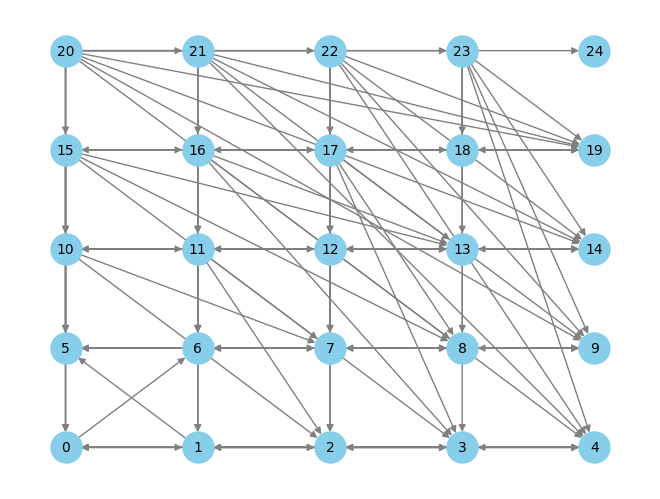

In [11]:
G= build_feasible_circuit_connectivity_graph(5, directed=True)
draw_graph_custom(G, layout='grid', node_size=500, font_size=10)

In [12]:
n=8
graph = build_feasible_circuit_connectivity_graph(n, directed=True)
circ = tsp_feasible_circuit(n)
tree = dfs_spanning_tree(graph, root=n*(n-1), directed_tree=True)
gradient_graph(graph, alpha=0.01, layout='grid')

TypeError: gradient_graph() missing 1 required positional argument: 'embedding'

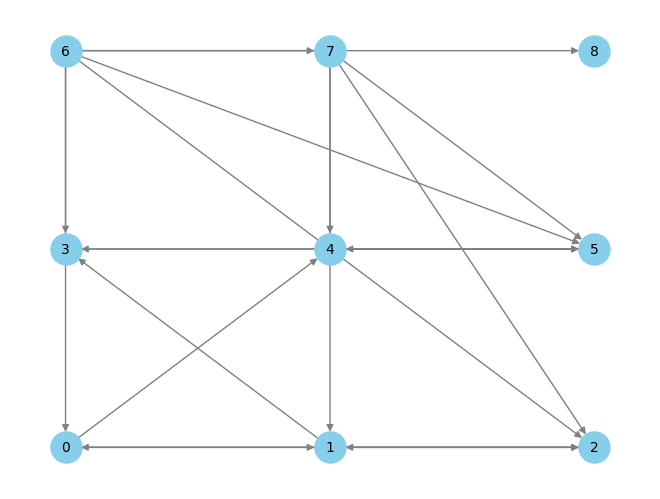

In [16]:
graph = build_feasible_circuit_connectivity_graph(3, directed=True)
draw_graph_custom(graph, layout='grid', node_size=500, font_size=10)

In [ ]:
n=5
graph = build_feasible_circuit_connectivity_graph(n, directed=True)
circ = tsp_feasible_circuit(n)
tree = dfs_spanning_tree(graph, root=n*(n-1), directed_tree=True)
# gradient_graph(tree, alpha=0.01, layout='kamada_kawai')
initial_mapping = initial_layout(tree, backend=FakeFez(), how='fiedler', topology='tree_dfs')
trivial_mapping = initial_layout(graph, backend=FakeFez(), how='trivial', topology='tree_dfs')
triv = custom_routed_circuit(circ, backend=FakeFez(), initial_mapping=trivial_mapping, swap_heuristic='lookahead', opt_level=3)
prop = custom_routed_circuit(circ, backend=FakeFez(), initial_mapping=initial_mapping, swap_heuristic='lookahead', opt_level=3)
gen = sabre_routed_circuit(circ, backend=FakeFez(), swap_heuristic='lookahead', opt_level=3)
print(triv.count_ops().get('swap',0),prop.count_ops().get('swap',0), gen.count_ops().get('swap',0))

C:\Users\devra\AppData\Local\Temp\ipykernel_40324\2089015483.py:163: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  adj_matrix = nx.adjacency_matrix(graph, nodelist=range(graph.number_of_nodes())).todense()


243 191 162


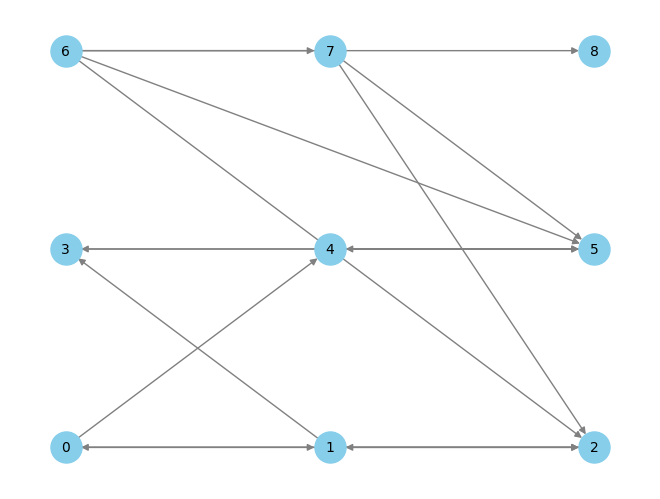

In [ ]:
# draw_graph_custom(graph, layout='grid', node_size=500, font_size=10)

In [ ]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
import numpy as np

def optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=None):
    """
    Find optimal mapping between logical and physical qubits
    using Hungarian algorithm on Euclidean distances.

    Args:
        logical_embedding: np.ndarray, shape (n, k)
        physical_embedding: np.ndarray, shape (n, k)

    Returns:
        mapping: dict {logical_index: physical_index}
    """
    if not nodes:
        nodes = list(range(physical_embedding.shape[0]))
    # cost matrix: pairwise distances between embeddings
    cost_matrix = cdist(logical_embedding, physical_embedding, metric='sqeuclidean')

    # Hungarian (linear sum assignment)
    row_ind, col_ind = linear_sum_assignment(cost_matrix)

    # Construct mapping
    mapping = {int(r): int(nodes[c]) for r, c in zip(row_ind, col_ind)}
    return mapping



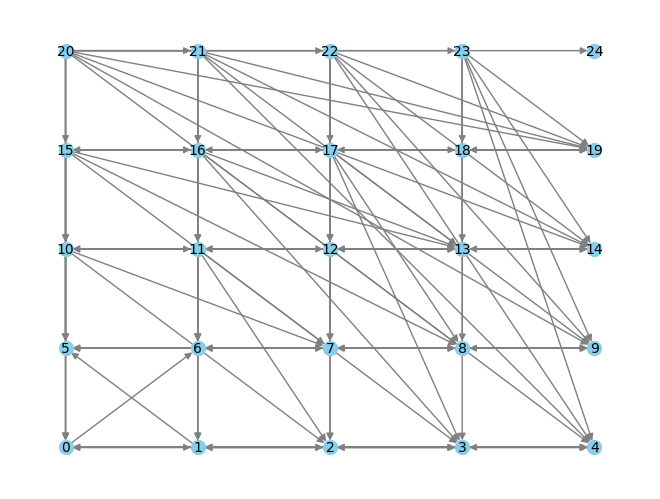

In [274]:
n=5
graph = build_feasible_circuit_connectivity_graph(n, directed=True)
draw_graph_custom(graph, layout='grid', font_size=10)

[[-0.18116183  0.17043716]
 [-0.1795055   0.16991175]
 [-0.19443488  0.15663197]
 [-0.19275288  0.16755613]
 [-0.19332888  0.17024667]
 [-0.19412243  0.17196515]
 [-0.19481202  0.17315141]
 [-0.19536205  0.17399483]
 [-0.19579312  0.17460938]
 [-0.19628406  0.17525148]
 [ 0.18347038  0.03003279]
 [ 0.18550416  0.02920583]
 [ 0.18508966  0.01837838]
 [ 0.18791212  0.02410037]
 [ 0.18961244  0.02490693]
 [ 0.19076853  0.02529231]
 [ 0.19156859  0.02552106]
 [ 0.19213397  0.02566916]
 [ 0.19254302  0.02577008]
 [ 0.19296612  0.02586703]
 [-0.11949365 -0.23360595]
 [-0.11716202 -0.22679443]
 [-0.1310118  -0.26626279]
 [-0.12660419 -0.25161357]
 [-0.1265493  -0.25311674]
 [-0.12696104 -0.25494679]
 [-0.12740509 -0.25646473]
 [-0.12779092 -0.25764569]
 [-0.12810849 -0.25855603]
 [-0.12848938 -0.25956868]
 [-0.06600644 -0.05502543]
 [-0.06527322 -0.05372511]
 [-0.06527322 -0.05372511]
 [-0.06936544 -0.06034273]
 [-0.06811457 -0.05828482]
 [-0.06783301 -0.05812436]
 [-0.06783267 -0.05822264]
 

C:\Users\devra\AppData\Local\Temp\ipykernel_40324\3630237161.py:70: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  adj_matrix = nx.adjacency_matrix(G, nodelist=G.nodes()).todense()


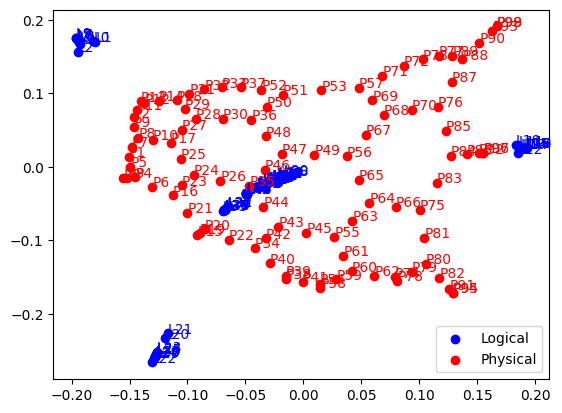

In [172]:
import matplotlib.pyplot as plt

logical_embedding = directed_graph_embedding(graph, k=2, alpha=0.95)
print(logical_embedding)
# gnodes, logical_embedding = logical_mds_embedding(graph, k=2)
H = get_coupling_graph(FakeFez())
S = build_tree_cluster(H, source=H.number_of_nodes()//2, n=n*n)
physical_embedding = undirected_graph_embedding(S, k=2)

# Logical embedding
plt.scatter(logical_embedding[:,0], logical_embedding[:,1], c='blue', label='Logical')
for i, (x, y) in enumerate(logical_embedding):
    plt.text(x, y, f'L{i}', color='blue')

# Physical embedding
plt.scatter(physical_embedding[:,0], physical_embedding[:,1], c='red', label='Physical')
for i, (x, y) in enumerate(physical_embedding):
    plt.text(x, y, f'P{i}', color='red')

plt.legend()
plt.show()


In [25]:
import networkx as nx
import numpy as np
from sklearn.manifold import MDS
from sklearn.cluster import KMeans

def cluster_physical_topology(H, n_clusters):
    # Step 1: compute all-pairs shortest path distance matrix
    nodes = list(H.nodes())
    N = len(nodes)
    D = np.zeros((N, N))
    for i, u in enumerate(nodes):
        lengths = nx.single_source_shortest_path_length(H, u)
        for j, v in enumerate(nodes):
            D[i, j] = lengths.get(v, np.inf)

    # Step 2: MDS embedding (2D for visualization)
    mds = MDS(n_components=2, dissimilarity='precomputed', random_state=0)
    embedding = mds.fit_transform(D)

    # Step 3: Cluster using KMeans
    kmeans = KMeans(n_clusters=n_clusters, random_state=0)
    labels = kmeans.fit_predict(embedding)

    # Step 4: Return clusters as sets of physical qubits
    clusters = {i: [] for i in range(n_clusters)}
    for node, label in zip(nodes, labels):
        clusters[label].append(node)

    return clusters

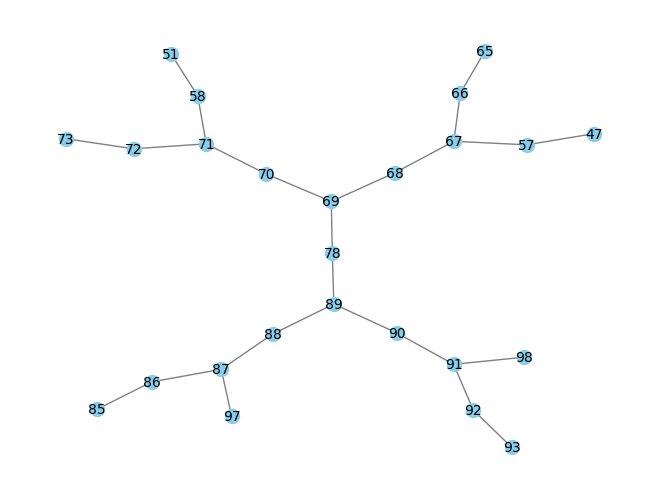

In [26]:
n=5
H = get_coupling_graph(FakeFez())
S = build_tree_cluster(H, source=H.number_of_nodes()//2, n=n*n)

clusters = bfs_subgraph_clusters(H, n_clusters=n, cluster_size=n, start_node=H.number_of_nodes()//2)
# print(clusters)
# draw_graph_custom(S, layout='kamada_kawai', font_size=10)
nodes=[]
for i in clusters:
    nodes+=i
s = H.subgraph(nodes)
draw_graph_custom(s, layout='kamada_kawai', font_size=10)
# cluster_physical_topology(S, n_clusters=n)

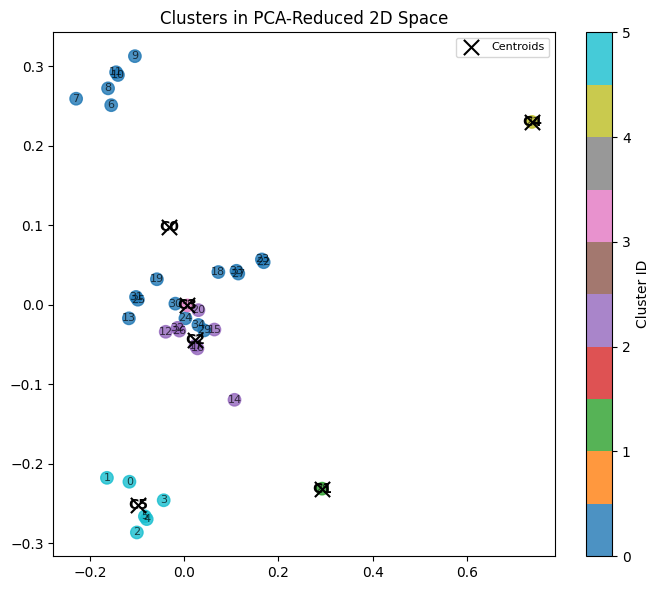

({np.int32(5): [0, 1, 2, 3, 4, 5],
  np.int32(0): [6,
   7,
   8,
   9,
   10,
   11,
   13,
   18,
   19,
   22,
   23,
   24,
   25,
   27,
   29,
   30,
   31,
   33,
   34],
  np.int32(2): [12, 14, 15, 16, 17, 20, 26, 32],
  np.int32(4): [21],
  np.int32(1): [28],
  np.int32(3): [35]},
 [0, 2, 5, 4, 1, 3])

In [27]:
n=6
graph = build_feasible_circuit_connectivity_graph(n, directed=False)
logical_embedding = graph_laplacian_embedding(graph, k=n-1, alpha=0.95)
clusters, ordered_clusters, pca_coords = cluster_and_order_by_pca(nodes=list(range(n*n)), Y=logical_embedding, num_clusters=n, plot=True, pca_space=True)
clusters, ordered_clusters




In [ ]:
graph = build_feasible_circuit_connectivity_graph(5, directed=True)
circ = tsp_feasible_circuit(5)
circ = circ.decompose(reps=2)
circ.draw('mpl', fold=-1)

C:\Users\devra\AppData\Local\Temp\ipykernel_9368\3358237638.py:476: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in circuit.data:


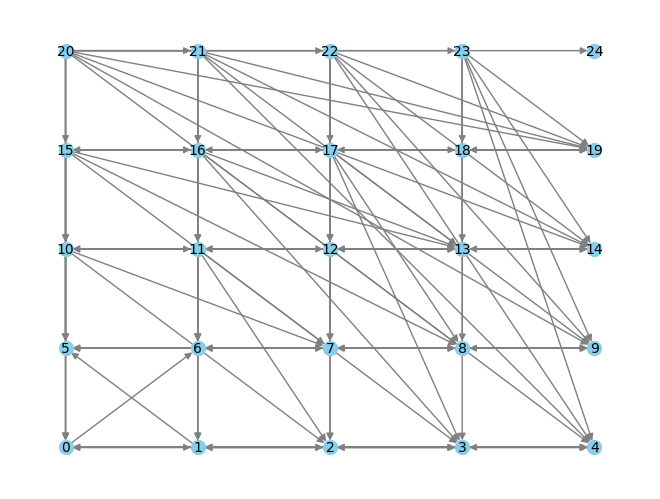

In [28]:
n=5
circ = tsp_feasible_circuit(n)
circ = circ.decompose(reps=2)
adj = temporal_interaction_matrix(circ)
graph = nx.from_numpy_array(adj)
draw_graph_custom(G, layout='grid', font_size=10)
# logical_embedding = graph_laplacian_embedding(graph, k=n-1, alpha=0.95)
# clusters, ordered_clusters, pca_coords = cluster_and_order_by_pca(nodes=list(range(n*n)), Y=logical_embedding, num_clusters=n, plot=True, pca_space=False)
# clusters, ordered_clusters

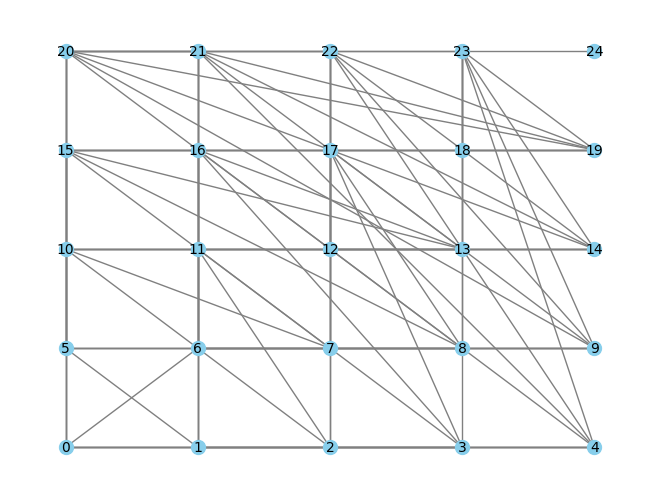

In [347]:
build_feasible_circuit_connectivity_graph(5)
draw_graph_custom(graph, layout='grid', font_size=10)

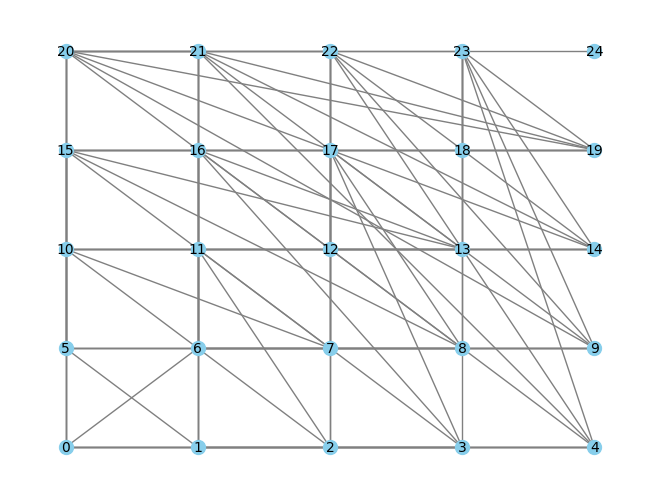

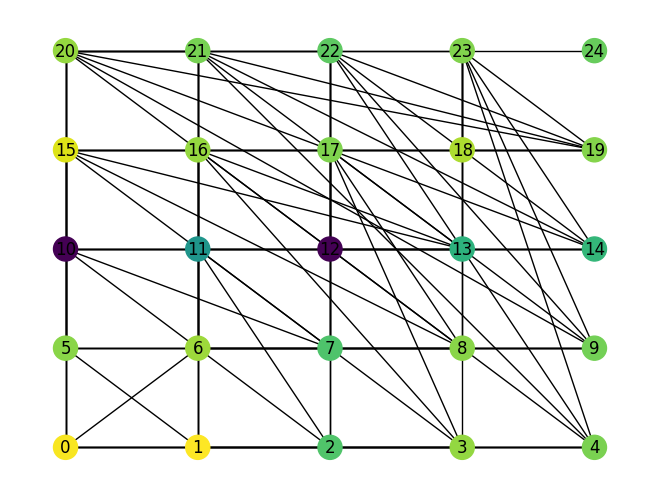

In [131]:
n=5
circ = tsp_feasible_circuit(n)
circ = transpile(circ, basis_gates=FakeFez().basis_gates, seed_transpiler=0)
# adj = temporal_interaction_matrix(circ)
# graph = nx.from_numpy_array(adj)
graph = early_interaction_graph(circ)
# graph = interaction_graph_with_lookahead(circ, reverse_weight=0.1)
draw_graph_custom(graph, layout='grid', font_size=10)
gradient_graph(graph, normalized=True)


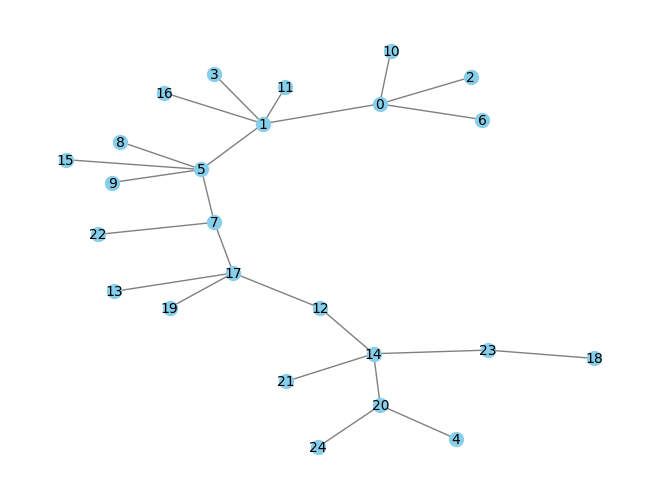

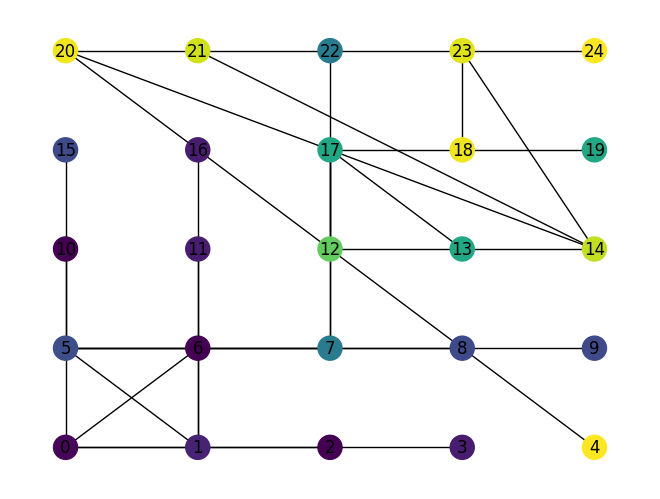

[0,
 1,
 6,
 2,
 10,
 5,
 11,
 3,
 16,
 7,
 8,
 15,
 9,
 17,
 22,
 12,
 13,
 19,
 14,
 20,
 21,
 23,
 24,
 4,
 18]

In [134]:
tree = weighted_dfs_spanning_tree(graph, root=0, branching=4)
# tree = dfs_spanning_tree(graph, root=0 directed_tree=True)
draw_graph_custom(tree, layout='kamada_kawai', font_size=10)
# print(graph_fiedler_sort(tree))
gradient_graph(tree)
# gradient_graph(graph)
weighted_bfs(tree, source=0)

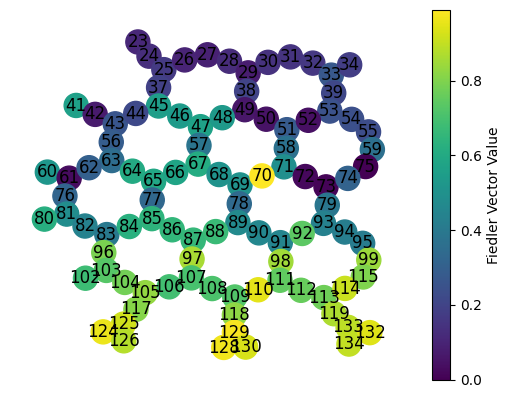

In [38]:
n=10
H = get_coupling_graph(FakeFez())
S = build_tree_cluster(H, source=H.number_of_nodes()//2, n=n*n)
# draw_graph_custom(S)
order = list(nx.dfs_preorder_nodes(S, source=H.number_of_nodes()//2))
pos = {node: i for i,node in enumerate(order)}
E = [pos[node]/(n*n) for node in S.nodes()]
gradient_graph(S, E)

In [529]:
graph.get_edge_data(16,17)['weight']

0.07692307692307693

In [502]:
recursively_sorted_nodes(10)

[0,
 1,
 10,
 11,
 20,
 21,
 22,
 2,
 12,
 30,
 31,
 32,
 33,
 3,
 13,
 23,
 40,
 41,
 42,
 43,
 44,
 4,
 14,
 24,
 34,
 50,
 51,
 52,
 53,
 54,
 55,
 5,
 15,
 25,
 35,
 45,
 60,
 61,
 62,
 63,
 64,
 65,
 66,
 6,
 16,
 26,
 36,
 46,
 56,
 70,
 71,
 72,
 73,
 74,
 75,
 76,
 77,
 7,
 17,
 27,
 37,
 47,
 57,
 67,
 80,
 81,
 82,
 83,
 84,
 85,
 86,
 87,
 88,
 8,
 18,
 28,
 38,
 48,
 58,
 68,
 78,
 90,
 91,
 92,
 93,
 94,
 95,
 96,
 97,
 98,
 99,
 9,
 19,
 29,
 39,
 49,
 59,
 69,
 79,
 89]

In [526]:
circ.draw('mpl', fold=-1)

In [403]:
dag = circuit_to_dag(circ)
layers = list(dag.layers())
layers[1]['graph'].op_nodes()

[DAGOpNode(op=Instruction(name='rxx', num_qubits=2, num_clbits=0, params=[0.7853981633974482]), qargs=(<Qubit register=(25, "x"), index=0>, <Qubit register=(25, "x"), index=1>), cargs=()),
 DAGOpNode(op=Instruction(name='h', num_qubits=1, num_clbits=0, params=[]), qargs=(<Qubit register=(25, "x"), index=10>,), cargs=())]

In [126]:
from tqdm import tqdm
def count_swaps(backend=FakeFez(), n_list=list(range(3,11)), k=2, avg_over=10, use_fiedler=False, use_tree=False, branching=3, normalize_laplacian=True):
    swaps = {'means': {'trivial':[],'sabre':[], 'embed':[]},
            'stds': {'trivial':[],'sabre':[], 'embed':[]}}
    for n in tqdm(n_list):
        circ = tsp_feasible_circuit(n)
        circ = transpile(circ, basis_gates=backend.basis_gates, seed_transpiler=0)
        # adj = temporal_interaction_matrix(circ)
        graph = early_interaction_graph(circ)
        # graph = interaction_graph_with_lookahead(circ, reverse_weight=0.1)
        if use_tree:
            # tree = dfs_spanning_tree(graph, root=n*(n-1), directed_tree=True)
            tree = weighted_dfs_spanning_tree(graph, root=0, branching=branching)
            graph = tree
        trivial_mapping = initial_layout(graph, backend=backend, how='trivial', topology='tree_dfs')
        if use_fiedler:
            prop_mapping = initial_layout(graph, backend=backend, how='fiedler', topology='tree_dfs')
        else:
            H = get_coupling_graph(backend)
            logical_embedding = graph_laplacian_embedding(graph, k=k, normalized=normalize_laplacian)
            logical_embedding = logical_embedding[:, :k]
            S = build_tree_cluster(H, source=backend.num_qubits//2, n=n*n)
            physical_embedding = graph_laplacian_embedding(S, k=k)

            # if k>2:
            #     num_extra_cols = k - 2
            #     physical_embedding = np.hstack([physical_embedding, np.zeros((physical_embedding.shape[0], num_extra_cols))])

            prop_mapping = optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=sorted(S.nodes()))
        circ = tsp_feasible_circuit(n)
        circ.measure_all()

        runs = {'trivial':[],'sabre':[], 'embed':[]}
        for _ in range(avg_over):
            trivial_circ = custom_routed_circuit(circ, backend=backend, initial_mapping=trivial_mapping, swap_heuristic='lookahead', opt_level=3)
            prop_circ = custom_routed_circuit(circ, backend=backend, initial_mapping=prop_mapping, swap_heuristic='lookahead', opt_level=3)
            gen_circ = sabre_routed_circuit(circ, backend=backend, swap_heuristic='lookahead', opt_level=3)

            runs['trivial'].append(trivial_circ.count_ops().get('swap',0))
            runs['sabre'].append(gen_circ.count_ops().get('swap',0))
            runs['embed'].append(prop_circ.count_ops().get('swap',0))

        swaps['means']['trivial'].append(np.mean(runs['trivial']))
        swaps['means']['sabre'].append(np.mean(runs['sabre']))
        swaps['means']['embed'].append(np.mean(runs['embed']))

        swaps['stds']['trivial'].append(np.std(runs['trivial']))
        swaps['stds']['sabre'].append(np.std(runs['sabre']))
        swaps['stds']['embed'].append(np.std(runs['embed']))
    return swaps

import matplotlib.pyplot as plt
import numpy as np

def plot_swap_counts(nodes, swaps):
# Example data
    methods = ["trivial", "sabre", "embed"]

    # Plot
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps['means'][method])
        std = np.array(swaps['stds'][method])
        plt.plot(nodes, mean, label=method)  # line for mean
        plt.fill_between(nodes, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("n", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

100%|██████████| 8/8 [00:24<00:00,  3.12s/it]


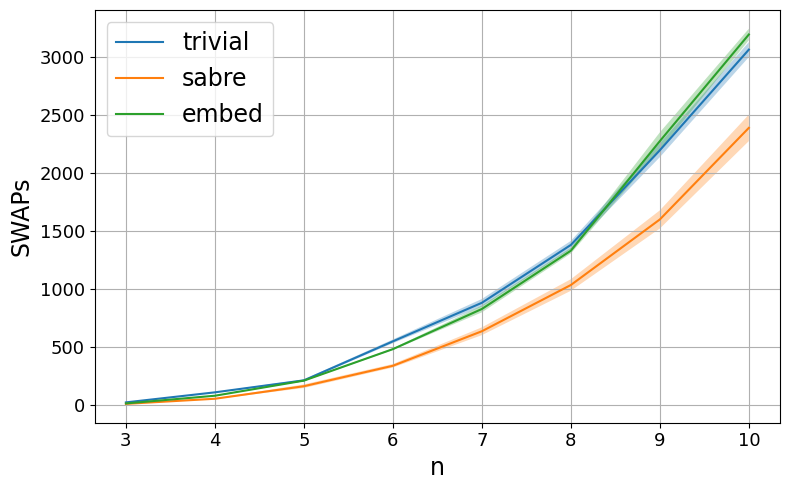

In [127]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=2, avg_over=10, use_fiedler=False, use_tree=False, branching=2)
plot_swap_counts(nodes, swaps)

branching=2

100%|██████████| 8/8 [00:14<00:00,  1.87s/it]


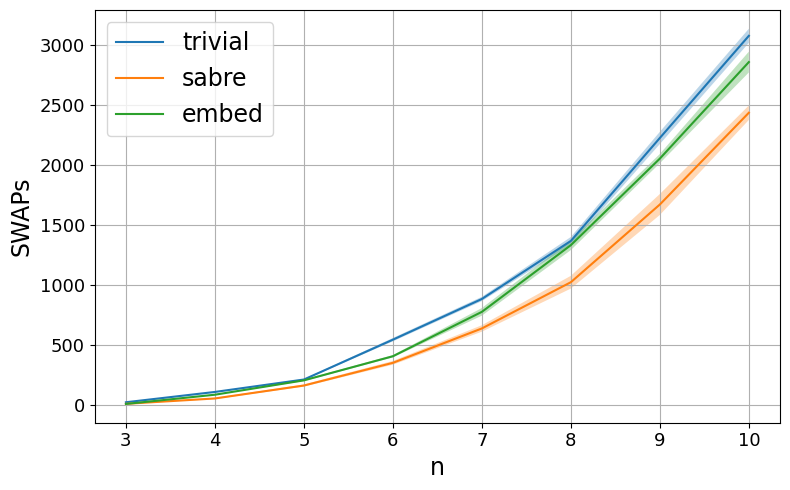

: 

In [ ]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=2, avg_over=10, use_fiedler=True, use_tree=True, branching=2)
plot_swap_counts(nodes, swaps)

100%|██████████| 8/8 [00:15<00:00,  1.94s/it]


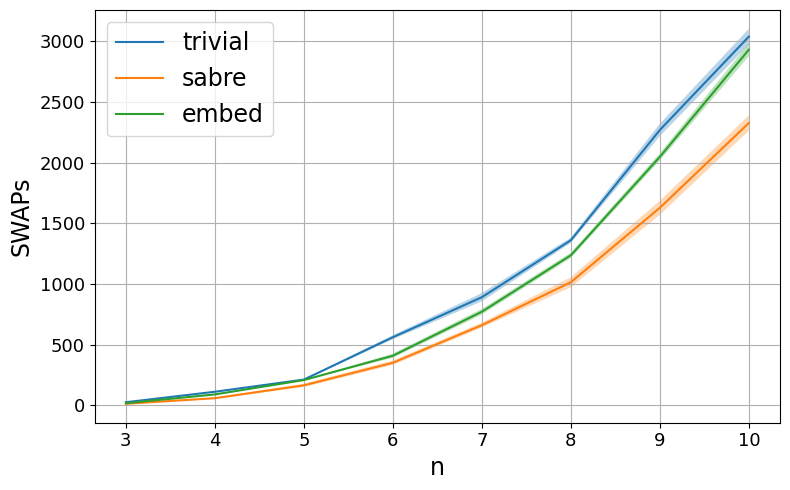

In [128]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=2, avg_over=10, use_fiedler=False, use_tree=True, branching=2)
plot_swap_counts(nodes, swaps)

100%|██████████| 8/8 [00:15<00:00,  1.88s/it]


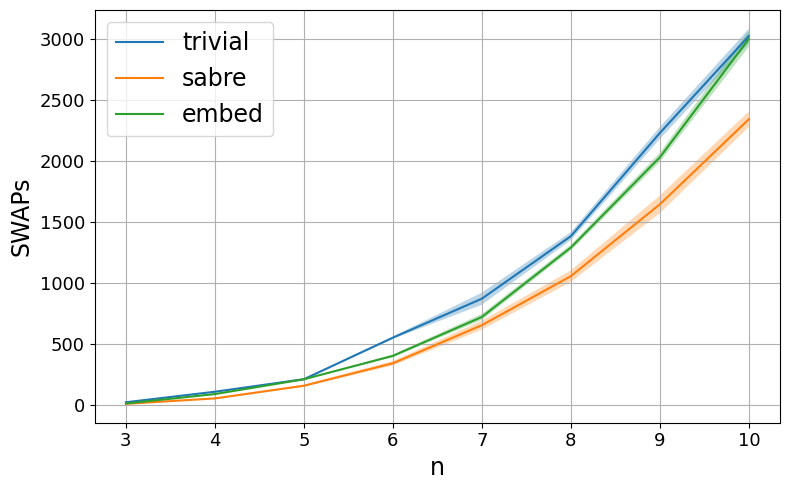

In [129]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=3, avg_over=10, use_fiedler=False, use_tree=True, branching=2)
plot_swap_counts(nodes, swaps)

branching=3

100%|██████████| 8/8 [00:16<00:00,  2.07s/it]


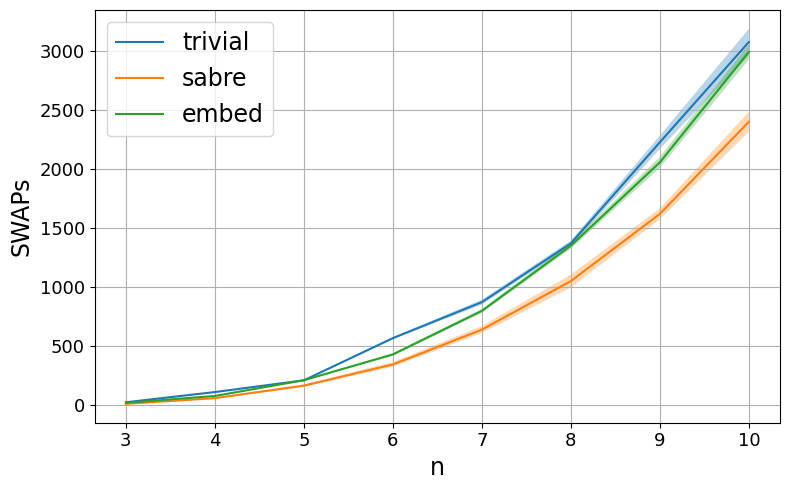

In [78]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=2, avg_over=10, use_fiedler=True, use_tree=True, branching=3)
plot_swap_counts(nodes, swaps)

100%|██████████| 8/8 [00:14<00:00,  1.87s/it]


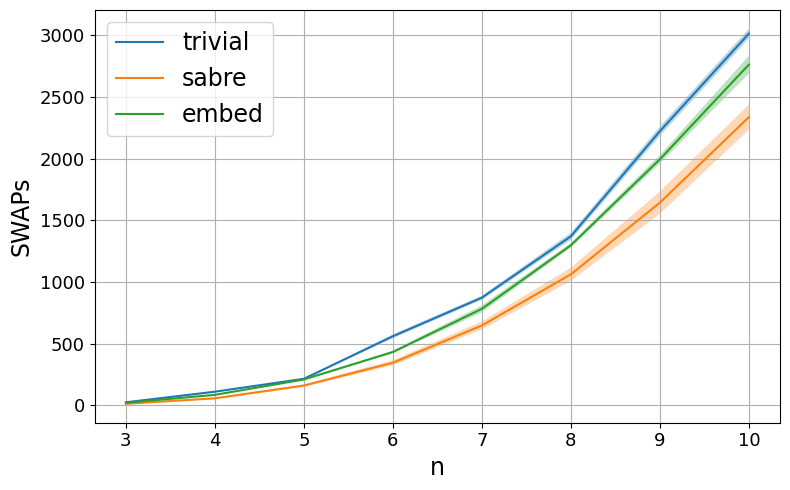

In [81]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=2, avg_over=10, use_fiedler=False, use_tree=True, branching=3)
plot_swap_counts(nodes, swaps)

100%|██████████| 8/8 [00:15<00:00,  1.88s/it]


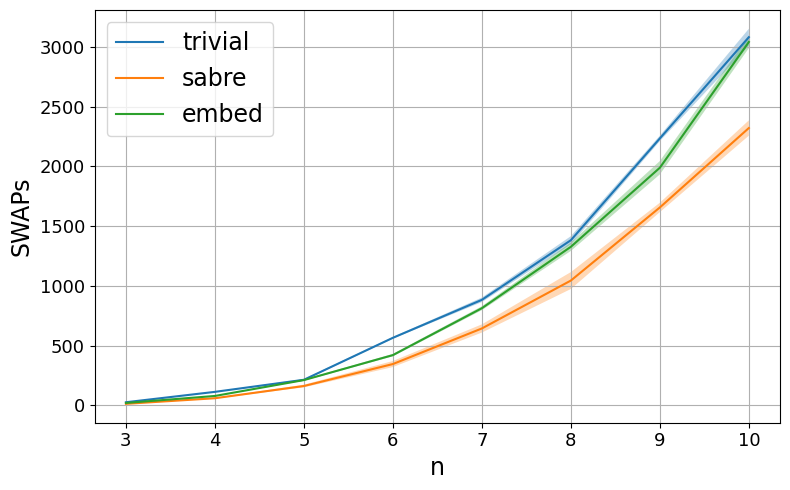

In [82]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=3, avg_over=10, use_fiedler=False, use_tree=True, branching=3)
plot_swap_counts(nodes, swaps)

branching=4

100%|██████████| 8/8 [00:16<00:00,  2.00s/it]


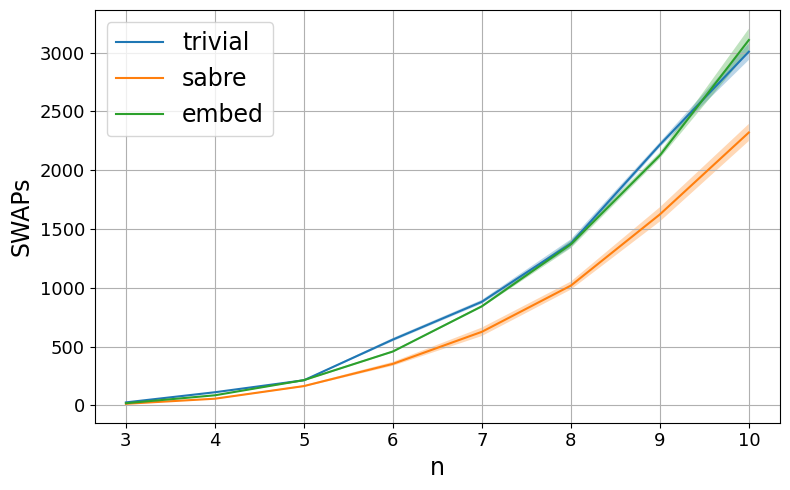

In [92]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=2, avg_over=10, use_fiedler=True, use_tree=True, branching=4)
plot_swap_counts(nodes, swaps)

100%|██████████| 8/8 [00:15<00:00,  1.90s/it]


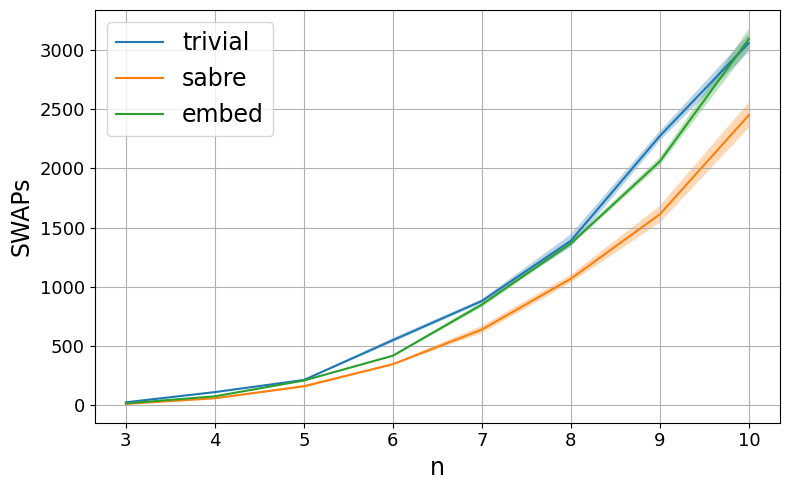

In [93]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=2, avg_over=10, use_fiedler=False, use_tree=True, branching=4)
plot_swap_counts(nodes, swaps)

100%|██████████| 8/8 [00:15<00:00,  1.90s/it]


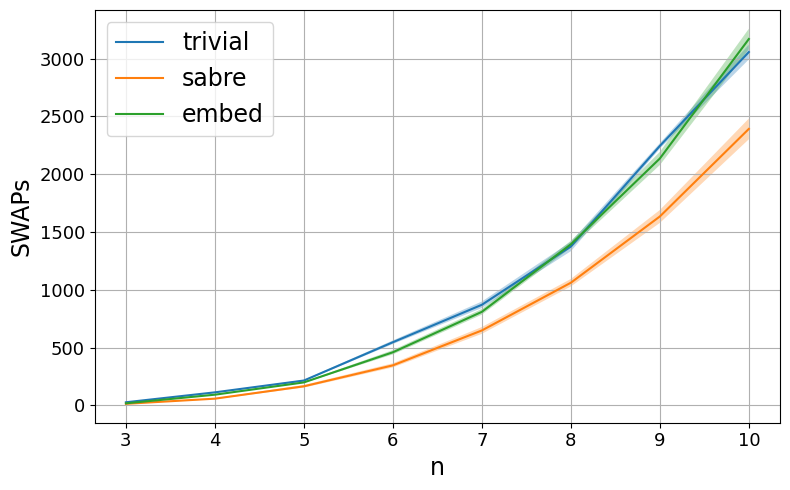

In [94]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=3, avg_over=10, use_fiedler=False, use_tree=True, branching=4)
plot_swap_counts(nodes, swaps)

branching=5

100%|██████████| 8/8 [00:15<00:00,  1.94s/it]


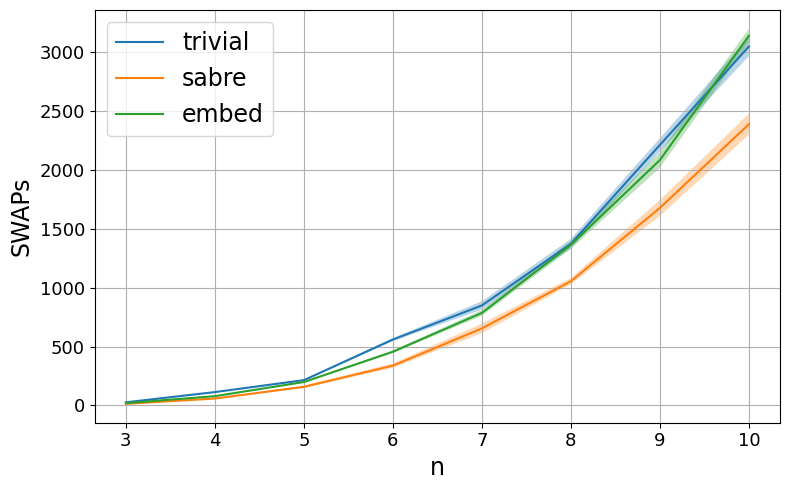

In [95]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=2, avg_over=10, use_fiedler=True, use_tree=True, branching=5)
plot_swap_counts(nodes, swaps)

100%|██████████| 8/8 [00:15<00:00,  1.88s/it]


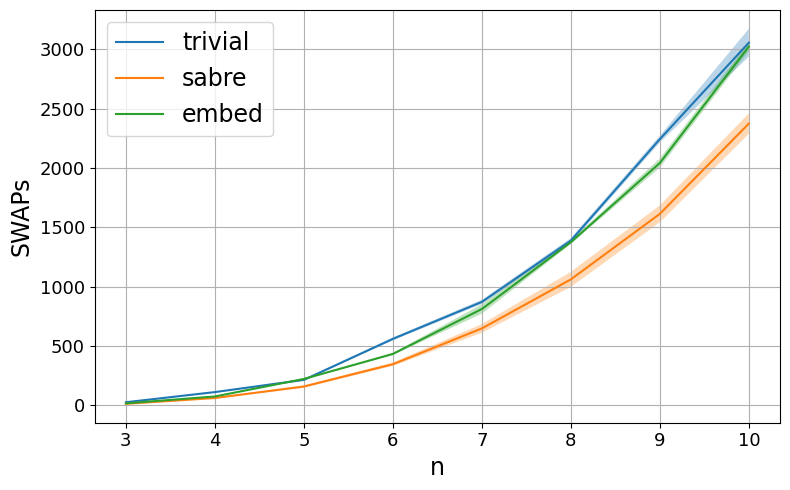

In [96]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=2, avg_over=10, use_fiedler=False, use_tree=True, branching=5)
plot_swap_counts(nodes, swaps)

100%|██████████| 8/8 [00:15<00:00,  1.98s/it]


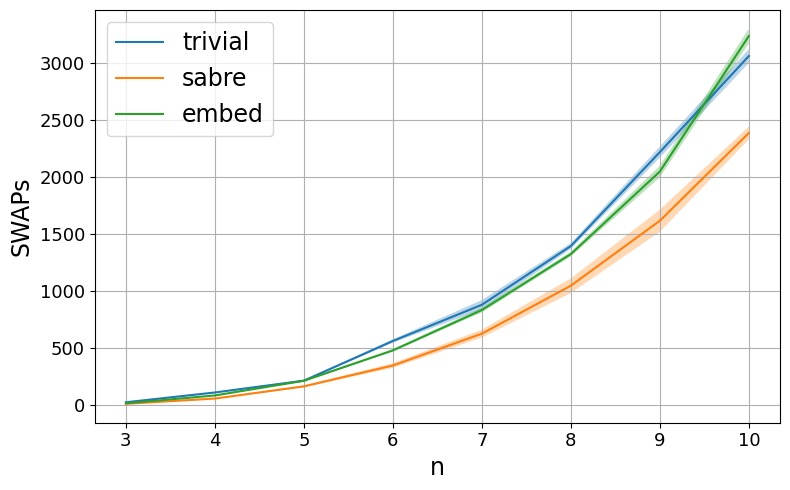

In [97]:
nodes = list(range(3,11))
swaps = count_swaps(n_list=nodes, k=3, avg_over=10, use_fiedler=False, use_tree=True, branching=5)
plot_swap_counts(nodes, swaps)




In [172]:
dec = transpile(circ, basis_gates=FakeFez().configuration().basis_gates)
dec.draw('mpl', fold=-1)

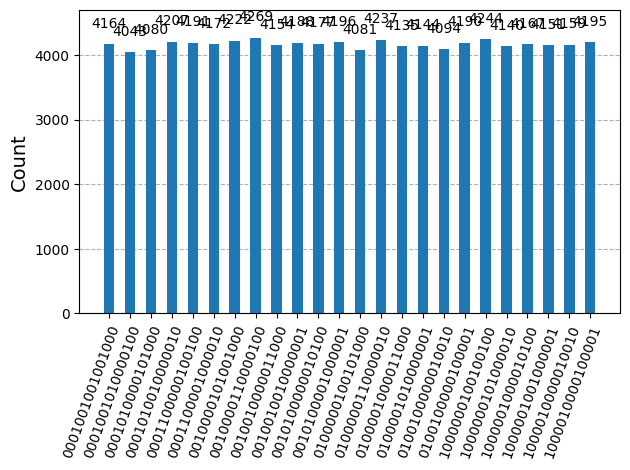

In [173]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
sim  = AerSimulator()
# circ=qc
circ=circ.decompose(reps=3)
result = sim.run(circ, shots=100000).result()
plot_histogram(result.get_counts())

In [5]:
import tsplib95
import numpy as np
from itertools import product

from qiskit import QuantumCircuit, QuantumRegister

# -----------------------
# Load TSP instance
# -----------------------
def load_tsp_instance(path: str):
    problem = tsplib95.load(path)
    n = len(list(problem.get_nodes()))
    dist = np.zeros((n, n))
    for i, j in product(range(n), range(n)):
        if i != j:
            dist[i, j] = problem.get_weight(i+1, j+1)
    return dist

# -----------------------
# Cost Hamiltonian (PauliSumOp)
# -----------------------
import numpy as np
from qiskit.quantum_info import SparsePauliOp

def tsp_cost_hamiltonian(dist_matrix):
    n = dist_matrix.shape[0]
    N = n * n

    # Build terms
    pauli_terms = []
    coeffs = []

    def qubit(city, pos):
        return city * n + pos  # flatten (row=city, col=pos)

    def Z_term(idx):
        """Return Pauli Z acting on qubit idx as SparsePauliOp."""
        s = ["I"] * N
        s[N - idx - 1] = "Z"  # Qiskit’s little-endian ordering
        return "".join(s)

    # x = (I - Z)/2
    def x_var(idx):
        return [("I" * N, 0.5), (Z_term(idx), -0.5)]

    # Distance terms
    for j in range(n):
        for k in range(n):
            if j != k:
                w = dist_matrix[j, k]
                if w != 0:
                    for pos in range(n - 1):
                        q1 = qubit(j, pos)
                        q2 = qubit(k, pos + 1)

                        # Expand (I - Z1)/2 * (I - Z2)/2
                        terms1 = x_var(q1)
                        terms2 = x_var(q2)
                        for (p1, c1) in terms1:
                            for (p2, c2) in terms2:
                                # multiply paulis p1 * p2
                                p_string = list("I" * N)
                                for idx, pauli in enumerate(p1):
                                    if pauli != "I":
                                        p_string[idx] = pauli
                                for idx, pauli in enumerate(p2):
                                    if pauli != "I":
                                        if p_string[idx] == "I":
                                            p_string[idx] = pauli
                                        elif p_string[idx] != pauli:
                                            raise ValueError("Non-commuting Z terms? should not happen")
                                pauli_terms.append("".join(p_string))
                                coeffs.append(w * c1 * c2)

    # Build SparsePauliOp
    H = SparsePauliOp(pauli_terms, coeffs)
    return H.simplify()

# -----------------------
# Cost unitary layer
# -----------------------
from qiskit.circuit.library import PauliEvolutionGate

def tsp_cost_unitary(qc: QuantumCircuit, dist_matrix, gamma, data_qubits):
    H = tsp_cost_hamiltonian(dist_matrix)  # SparsePauliOp
    # build evolution gate exp(-i * gamma * H)
    cost_gate = PauliEvolutionGate(H, time=gamma)
    qc.append(cost_gate, data_qubits)
    return qc


# -----------------------
# Mixer (from tsp_feasible_circuit)
# -----------------------
def mcphase_on_zero(qc: QuantumCircuit, data_qubits, ancilla_qubit, beta):
    for q in data_qubits:
        qc.x(q)
    qc.mcx(data_qubits, ancilla_qubit)
    qc.rz(beta, ancilla_qubit)
    qc.mcx(data_qubits, ancilla_qubit)
    for q in data_qubits:
        qc.x(q)

def mixer_from_UF(UF: QuantumCircuit, beta: float):
    N = UF.num_qubits
    qc = QuantumCircuit(N + 1, name=f"UM_{beta:.2f}")
    data = list(range(N))
    anc = N
    qc.append(UF.to_gate(label="UF"), data)
    mcphase_on_zero(qc, data, anc, beta)
    qc.append(UF.inverse().to_gate(label="UFdg"), data)
    return qc.to_gate()

# -----------------------
# Full QAOA circuit
# -----------------------
def qaoa_tsp_feasible(n, dist_matrix, gammas, betas):
    UF = tsp_feasible_circuit(n)
    N = n * n
    data = QuantumRegister(N, "x")
    anc = QuantumRegister(1, "anc")
    qc = QuantumCircuit(data, anc)

    # Initialization
    qc.append(UF.to_gate(label="UF_init"), data)

    p = len(gammas)
    for layer in range(p):
        gamma = gammas[layer]
        beta = betas[layer]

        # Cost unitary
        qc = tsp_cost_unitary(qc, dist_matrix, gamma, data)

        # Mixer
        UM = mixer_from_UF(UF, beta)
        qc.append(UM, data[:] + anc[:])

    return qc


In [6]:
import numpy as np

def random_euclidean_tsp(n_cities, seed=None):
    rng = np.random.default_rng(seed)
    # Generate random coordinates in [0,1]x[0,1]
    coords = rng.random((n_cities, 2))
    # Distance matrix (Euclidean)
    dist = np.linalg.norm(coords[:, None, :] - coords[None, :, :], axis=-1)
    np.fill_diagonal(dist, 0)  # no self-loops
    return coords, dist
coords, dist = random_euclidean_tsp(3, seed=42)
print("Coordinates:\n", coords)
print("Distance matrix:\n", dist)


Coordinates:
 [[0.77395605 0.43887844]
 [0.85859792 0.69736803]
 [0.09417735 0.97562235]]
Distance matrix:
 [[0.         0.2719947  0.86613689]
 [0.2719947  0.         0.81348895]
 [0.86613689 0.81348895 0.        ]]


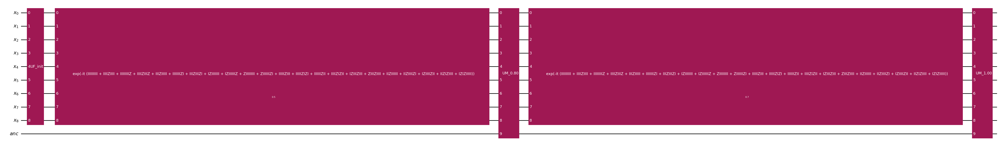

In [7]:

# Example params
gammas = [0.5, 0.7]
betas = [0.8, 1.0]

qc = qaoa_tsp_feasible(n=dist.shape[0], dist_matrix=dist,
                       gammas=gammas, betas=betas)
# qc = qc.decompose(reps=2)
qc.draw('mpl', fold=-1)


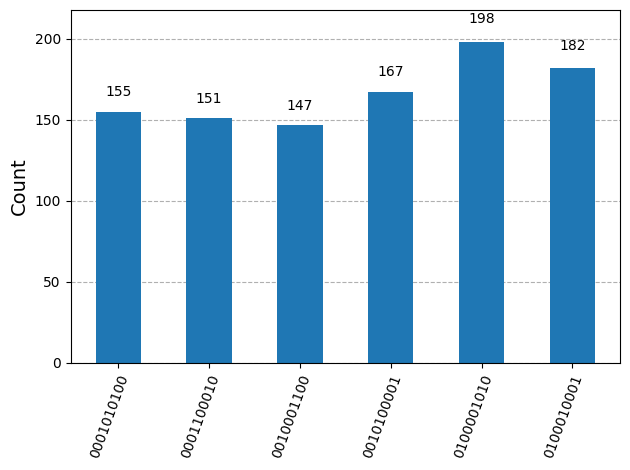

In [8]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
sim  = AerSimulator()
qc.measure_all()
circ=qc
circ=circ.decompose(reps=10)
result = sim.run(circ, shots=1000).result()
plot_histogram(result.get_counts())

In [ ]:
from qiskit_ibm_runtime.fake_provider import FakeTorino, FakeFez, FakeBrisbane
from qiskit import transpile

In [16]:
dec = transpile(qc, basis_gates=FakeFez().configuration().basis_gates)
dec.draw('mpl', fold=-1)